# Copy-paste augmentation: full-size preview

These are the **exact synthetic training images** the Aqua `prepare` job makes. It's the same
script with the same seeds, so the images are identical. Each one is shown at its real size,
**1280×720**, twice:

1. **As the model sees it**: try to spot the pasted fish before scrolling on.
2. **With the pasted fish outlined**: the pink outline is read back from the label file
   written for that image, so it also checks the label lines up with the fish.

If VS Code shrinks the images to fit the pane, widen the pane or open the files directly:
they're saved in `preview_data/synth_images/`. Preview on a Mac shows them at 100%.

Change the settings in the next cell and re-run to see different examples.

In [1]:
N_SAMPLES = 12            # how many synthetic images to show
SPECIES = "both"          # "both", "Forcepsfish" or "Moorish Idol"
SHOW_ORIGINAL = False     # also show the target frame BEFORE the paste
SEED = 0                  # change to get a different random selection

In [2]:
import csv
import random
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

import cv2
import numpy as np
from IPython.display import Image, Markdown, display


def _find_package_dir() -> Path:
    candidates = []
    nb_file = globals().get("__vsc_ipynb_file__")  # VS Code tells the kernel where the notebook is
    if nb_file:
        candidates.append(Path(nb_file).resolve().parent)
    cwd = Path.cwd()
    candidates += [cwd, cwd / "copy_paste_experiment"]
    p = cwd
    for _ in range(4):
        p = p.parent
        candidates += [p, p / "copy_paste_experiment"]
    candidates.append(Path.home() / "Desktop" / "EGH490-2_scripts" / "copy_paste_experiment")
    # a folder only counts if it has the whole package next to prepare_experiment.py AND the frames
    # one level up -- a stray prepare_experiment.py (e.g. a copy in Downloads) is skipped
    needed = ["prepare_experiment.py", "labels_export/data.yaml", "experiment_donors.csv",
              "approved_acceptor_frames.csv"]
    for c in candidates:
        if all((c / f).exists() for f in needed) and (c.parent / "full_dataset").is_dir():
            return c.resolve()
    raise FileNotFoundError("Couldn't find the unzipped copy_paste_experiment folder (with labels_export/ "
                            "inside and full_dataset/ next to it). Checked:\n  "
                            + "\n  ".join(map(str, candidates)))


PKG = _find_package_dir()
IMAGES_DIR = PKG.parent / "full_dataset"
PREVIEW = PKG / "preview_data"
print(f"experiment folder: {PKG}")
print(f"frames:            {IMAGES_DIR}")

experiment folder: ../copy_paste_experiment
frames:            ../full_dataset


## Generate the synthetic images

This runs `prepare_experiment.py` exactly as the Aqua job does (default settings), in a
temporary folder. It keeps only the synthetic images and their labels in `preview_data/`.
It takes about 10 seconds the first time and is skipped after that.

In [3]:
if not (PREVIEW / "synth_report.csv").exists():
    tmp = Path(tempfile.mkdtemp(prefix="cp_preview_"))
    out = subprocess.run([sys.executable, str(PKG / "prepare_experiment.py"),
                          "--images-dir", str(IMAGES_DIR), "--out", str(tmp / "data")],
                         cwd=PKG, capture_output=True, text=True)
    print(out.stdout[-2500:])
    if out.returncode != 0:
        print(out.stderr[-3000:])
        raise RuntimeError("prepare_experiment.py failed -- see the error above")
    PREVIEW.mkdir(exist_ok=True)
    shutil.copytree(tmp / "data" / "synth_images", PREVIEW / "synth_images", dirs_exist_ok=True)
    (PREVIEW / "labels").mkdir(exist_ok=True)
    for row in csv.DictReader(open(tmp / "data" / "synth_report.csv")):
        shutil.copy(tmp / "data" / "seg_copypaste" / "labels" / "train" / f"{row['synth']}.txt",
                    PREVIEW / "labels" / f"{row['synth']}.txt")
    for f in ("synth_report.csv", "split.csv", "prepare_summary.json"):
        shutil.copy(tmp / "data" / f, PREVIEW / f)
    shutil.rmtree(tmp, ignore_errors=True)
else:
    print(f"using the images already generated in {PREVIEW}")

report = list(csv.DictReader(open(PREVIEW / "synth_report.csv")))
print(f"{len(report)} synthetic images: "
      + ", ".join(f"{sp} {sum(r['species'] == sp for r in report)}"
                  for sp in sorted({r['species'] for r in report})))

frames 1000-2461: 1462 (1206 with labels, 256 background)
split (block=30, guard=15, seed=2): train 982, val 240, test 240 frames; 16 donor-protected blocks forced to train
  Forcepsfish      instances  train   56  val   16  test   21
  Moorish Idol     instances  train   85  val   29  test   29
  Forcepsfish      donors usable 23/23 (frames [163, 164, 165, 166, 939, 940, 941, 1603, 1604, 1605, 1606, 1661, 1662, 1667, 1668, 1779, 2098, 2132, 2161])
  Moorish Idol     donors usable 13/13 (frames [1166, 1167, 1168, 1169, 1170, 1172, 1545, 1646, 1648, 1668, 1669, 1670, 2381])
  Forcepsfish      acceptor frames (train, allowed view): 539
  Moorish Idol     acceptor frames (train, allowed view): 539
  Forcepsfish: wrote 150 synthetic images (0 used the matched-blend fallback)
  Moorish Idol: wrote 150 synthetic images (0 used the matched-blend fallback)

done -> /tmp/cp_preview_n_shbngh/data
  /tmp/cp_preview_n_shbngh/data/det_baseline.yaml
  /tmp/cp_preview_n_shbngh/data/det_copypaste.yaml

300 synthetic images: Forcepsfish 150, Moorish Idol 150


## The images

Each heading shows: the species; the frame the fish was cut from (**donor**); the frame it was
pasted into (**target**, always a training frame in an allowed camera view that already contains
that species); the rotation and flip applied; and where it was placed.

### 1. Forcepsfish: donor frame 164 → target frame 2458
rotated -7°, flipped horizontally; pasted fish is 55×82 px at x=646, y=247 · file `synth_Forcepsfish_0027_t2458_d164.jpg`

**As the model sees it**

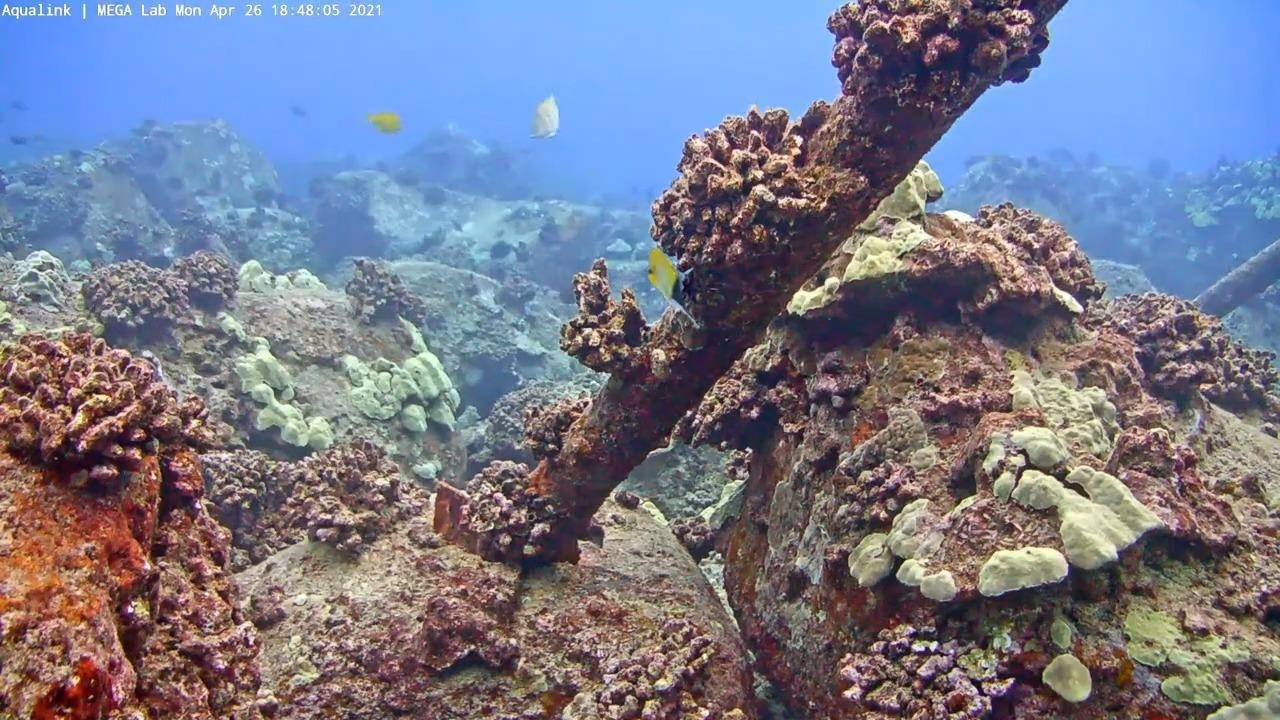

**Pasted fish outlined** (outline drawn from the label file)

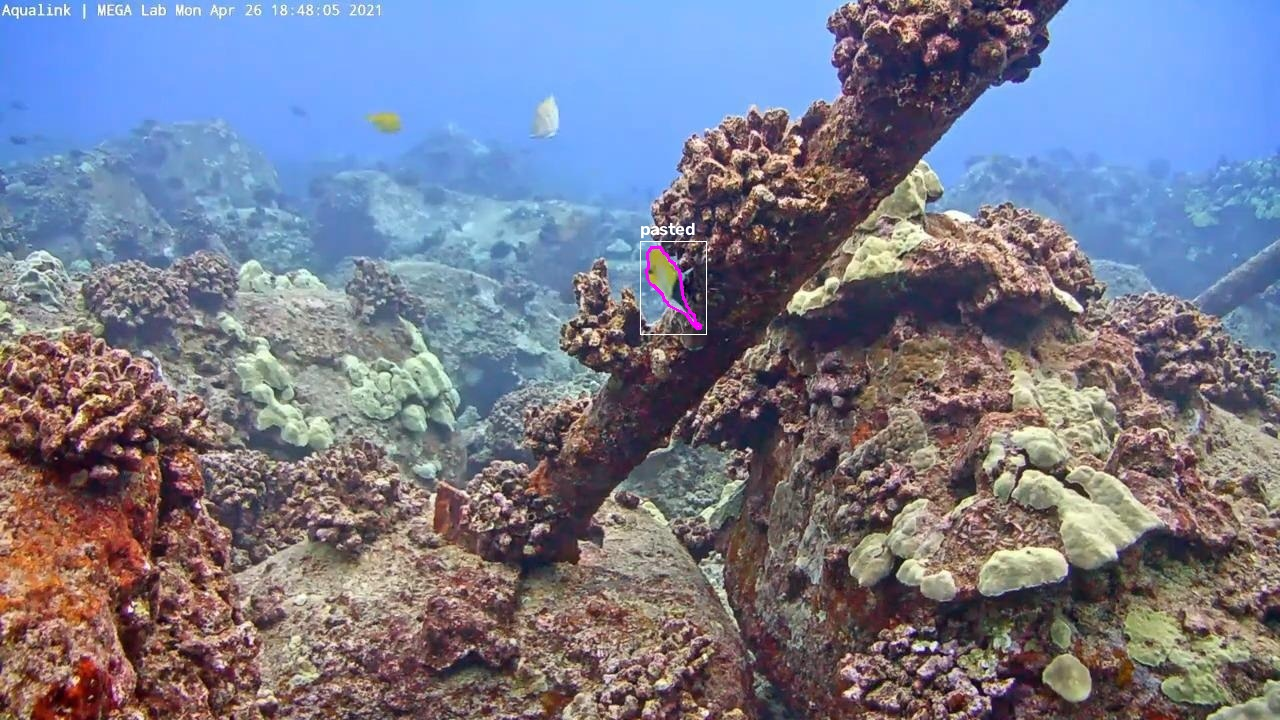

### 2. Moorish Idol: donor frame 1668 → target frame 1920
rotated +14°; pasted fish is 154×147 px at x=61, y=86 · file `synth_Moorish_Idol_0138_t1920_d1668.jpg`

**As the model sees it**

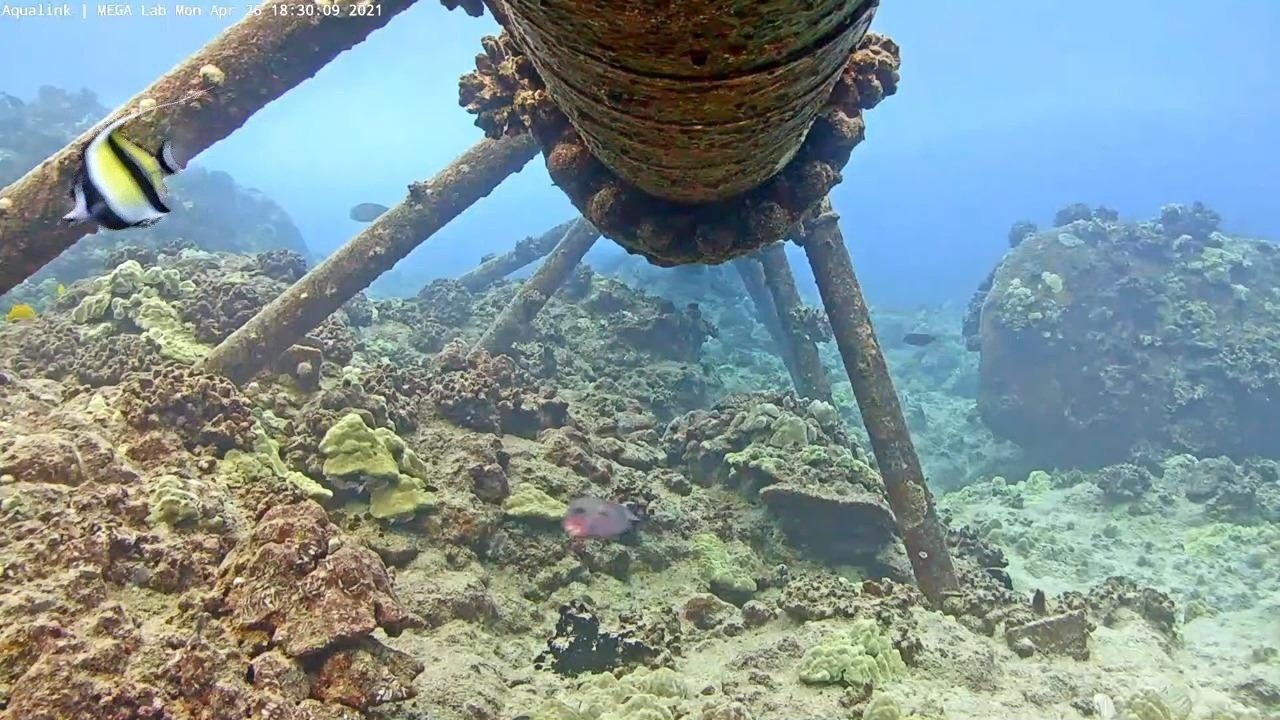

**Pasted fish outlined** (outline drawn from the label file)

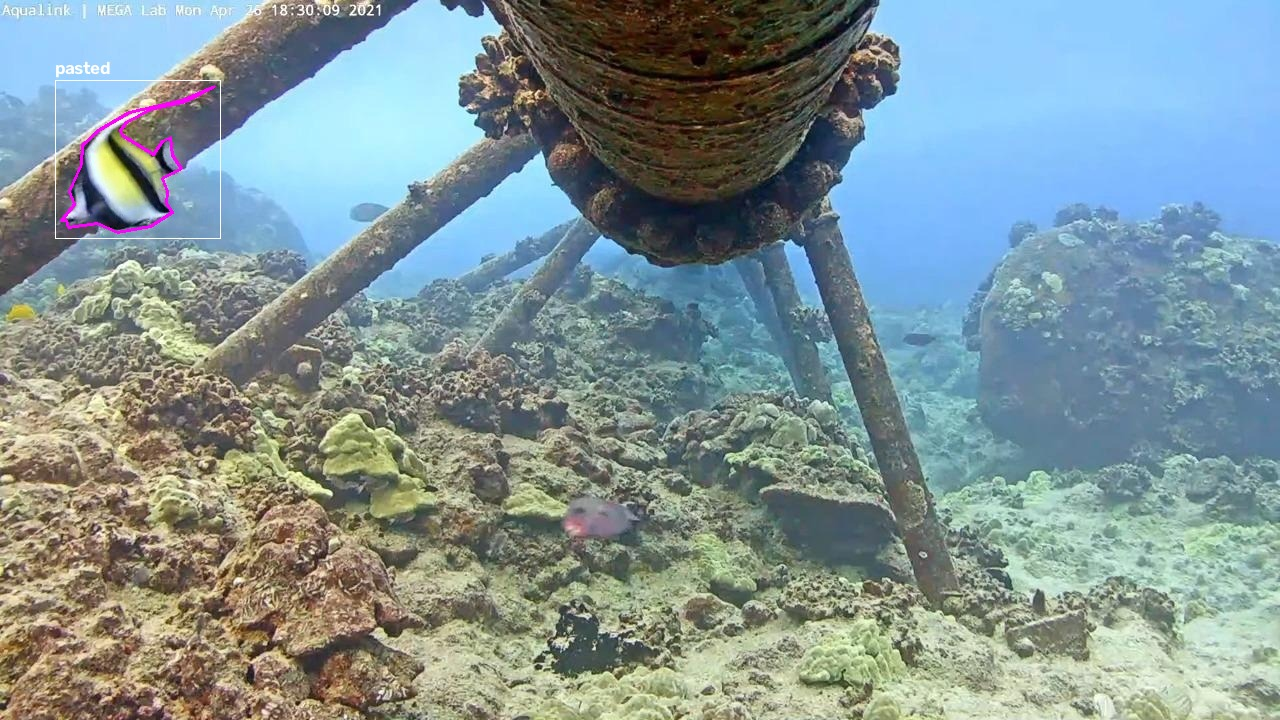

### 3. Forcepsfish: donor frame 1661 → target frame 1168
rotated -15°; pasted fish is 113×72 px at x=368, y=597 · file `synth_Forcepsfish_0050_t1168_d1661.jpg`

**As the model sees it**

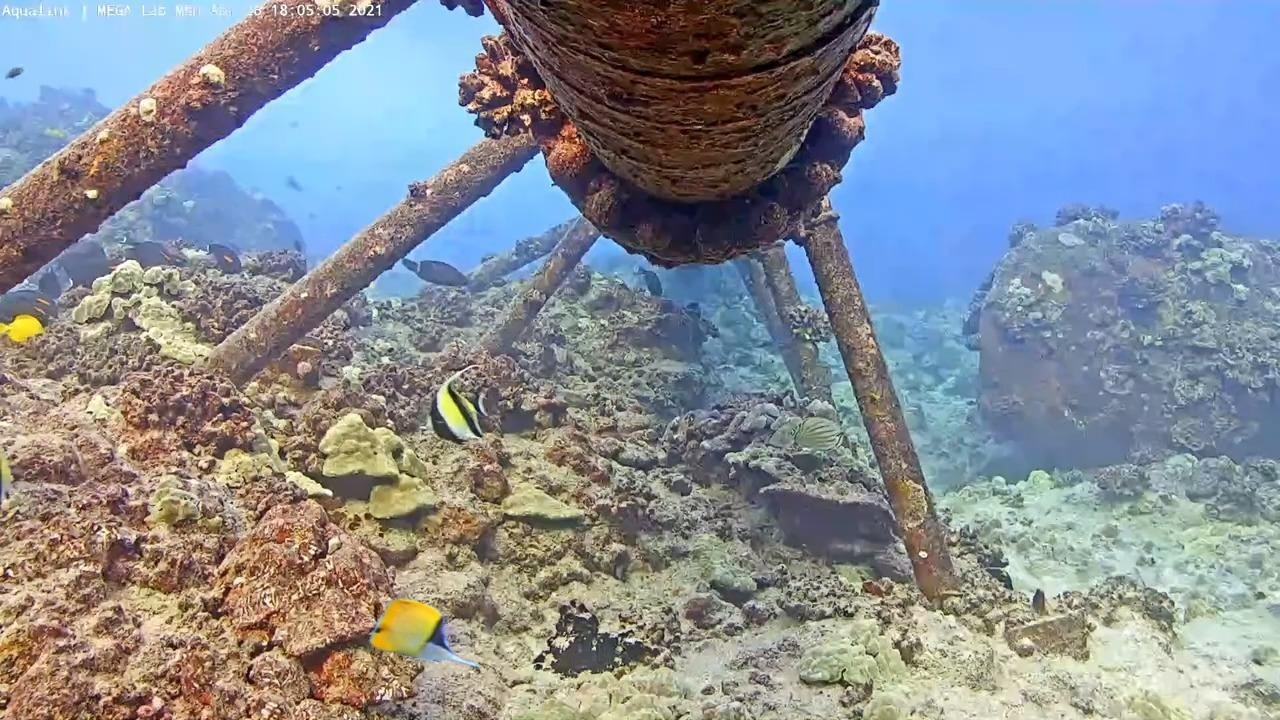

**Pasted fish outlined** (outline drawn from the label file)

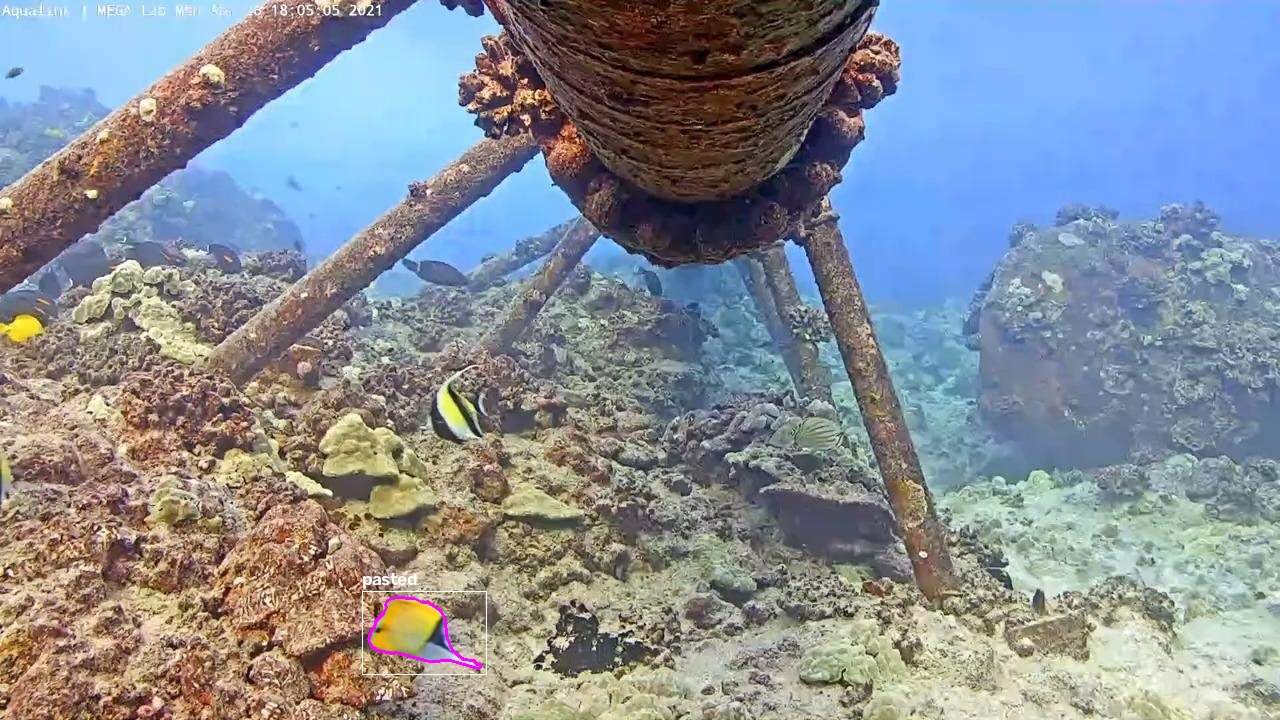

### 4. Moorish Idol: donor frame 2381 → target frame 1250
rotated -0°; pasted fish is 204×203 px at x=662, y=154 · file `synth_Moorish_Idol_0023_t1250_d2381.jpg`

**As the model sees it**

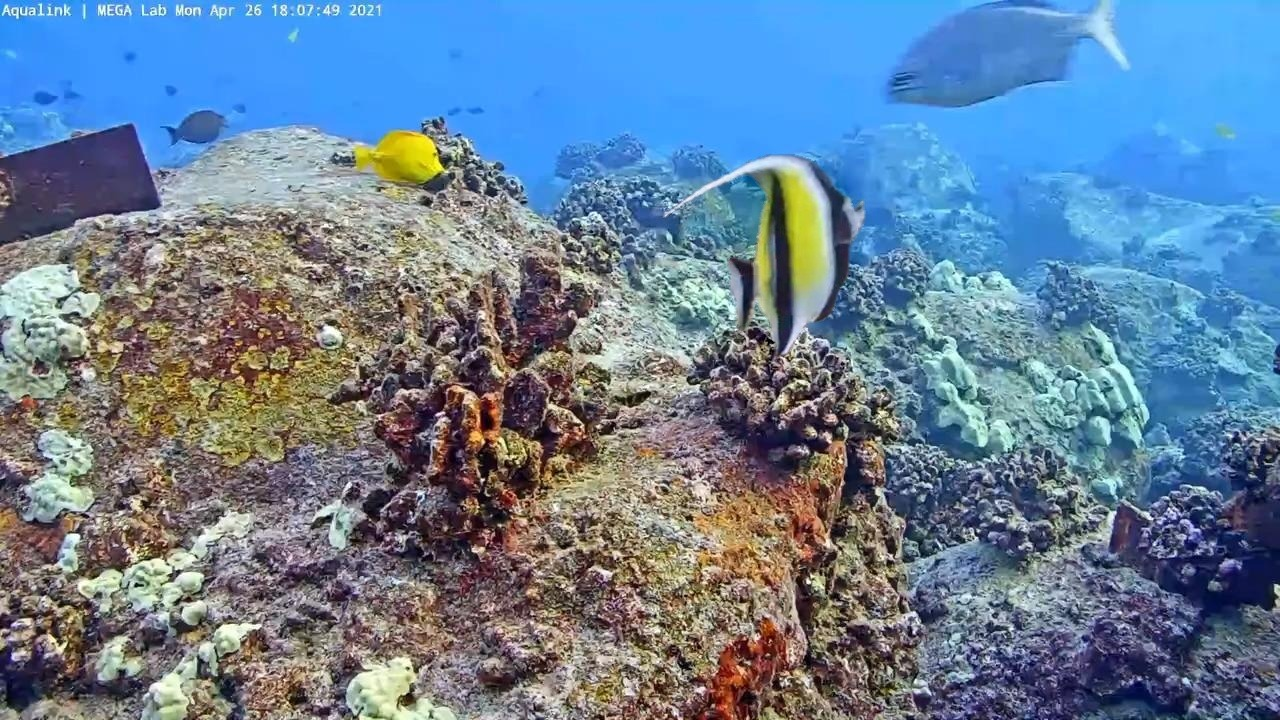

**Pasted fish outlined** (outline drawn from the label file)

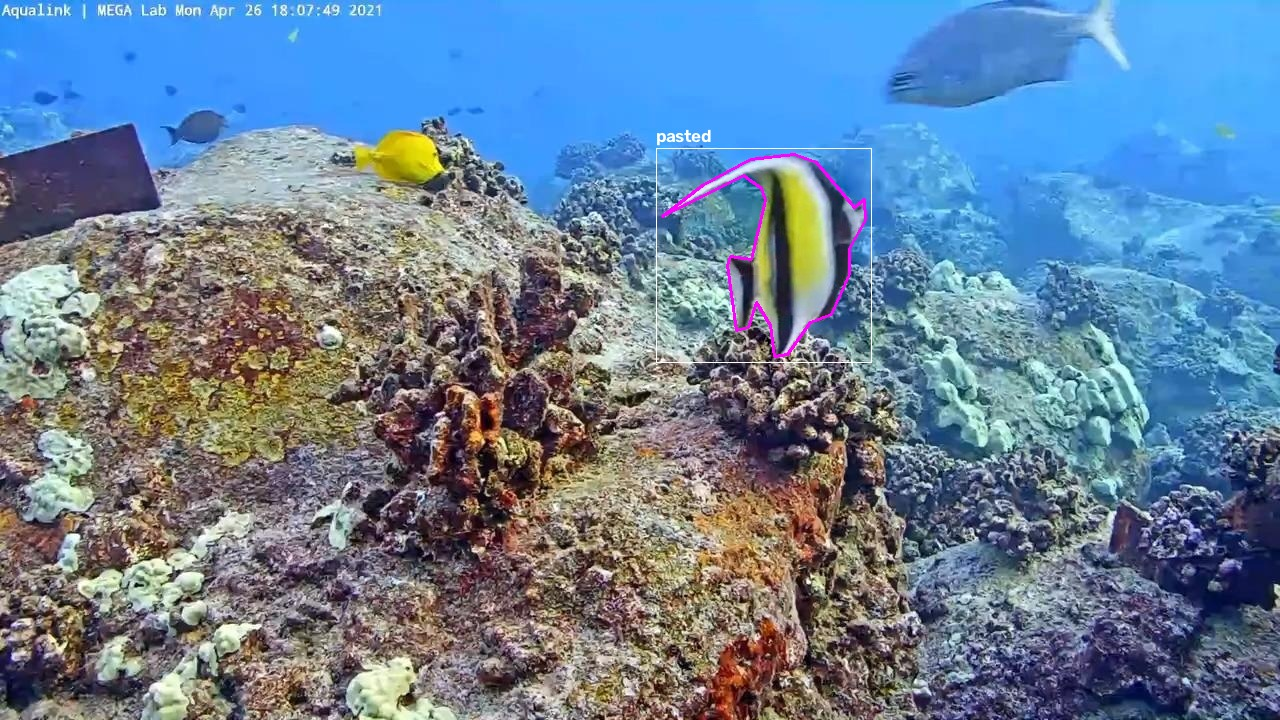

### 5. Forcepsfish: donor frame 166 → target frame 1619
rotated -10°; pasted fish is 107×57 px at x=6, y=535 · file `synth_Forcepsfish_0053_t1619_d166.jpg`

**As the model sees it**

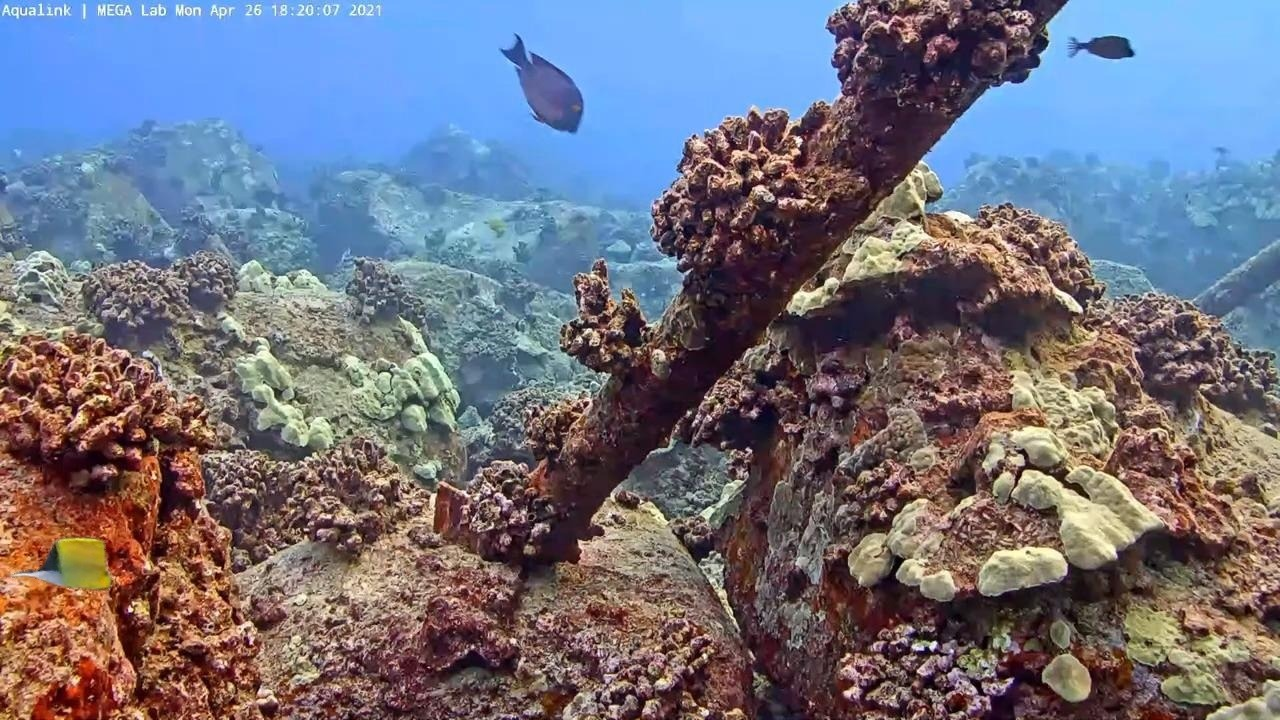

**Pasted fish outlined** (outline drawn from the label file)

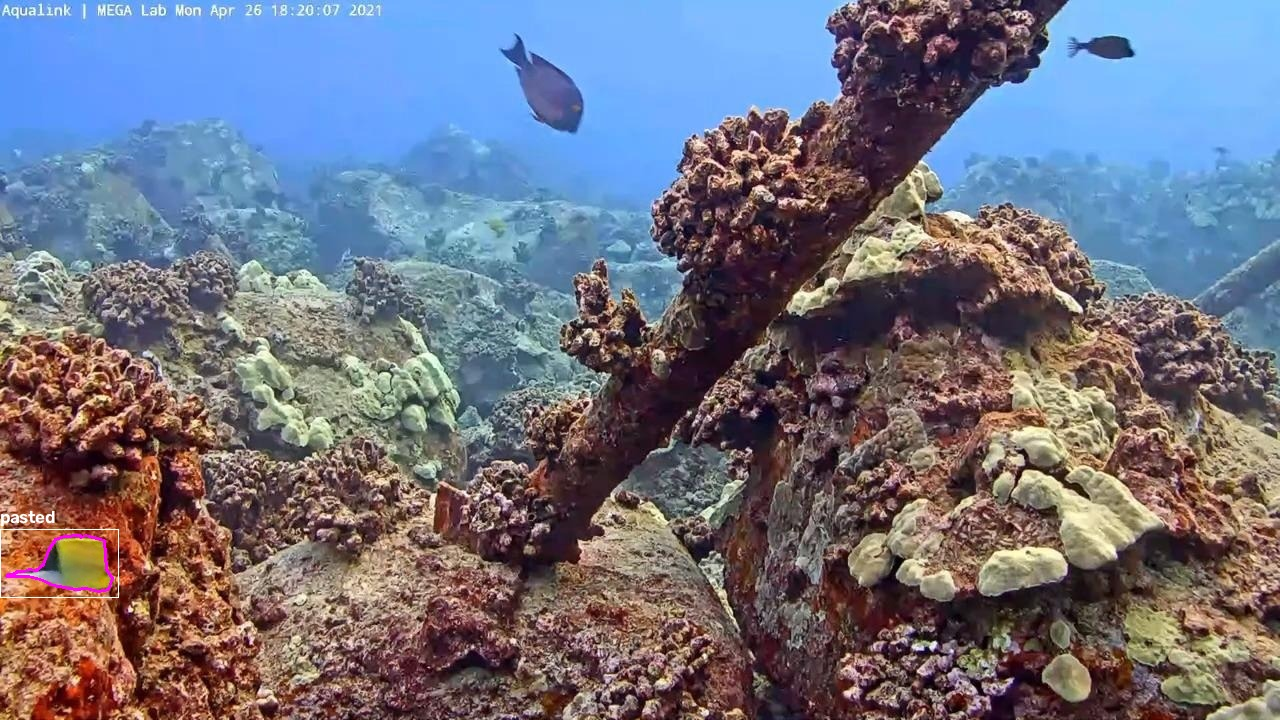

### 6. Moorish Idol: donor frame 1545 → target frame 1271
rotated +15°; pasted fish is 104×106 px at x=375, y=135 · file `synth_Moorish_Idol_0132_t1271_d1545.jpg`

**As the model sees it**

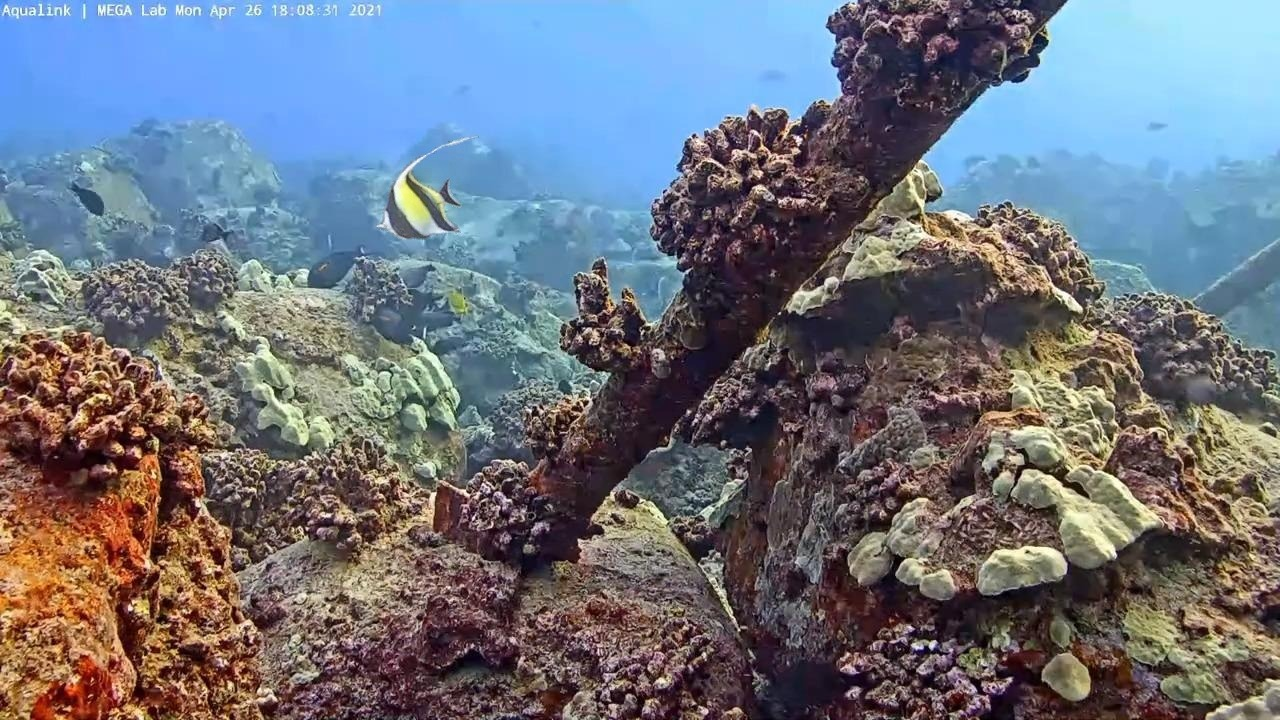

**Pasted fish outlined** (outline drawn from the label file)

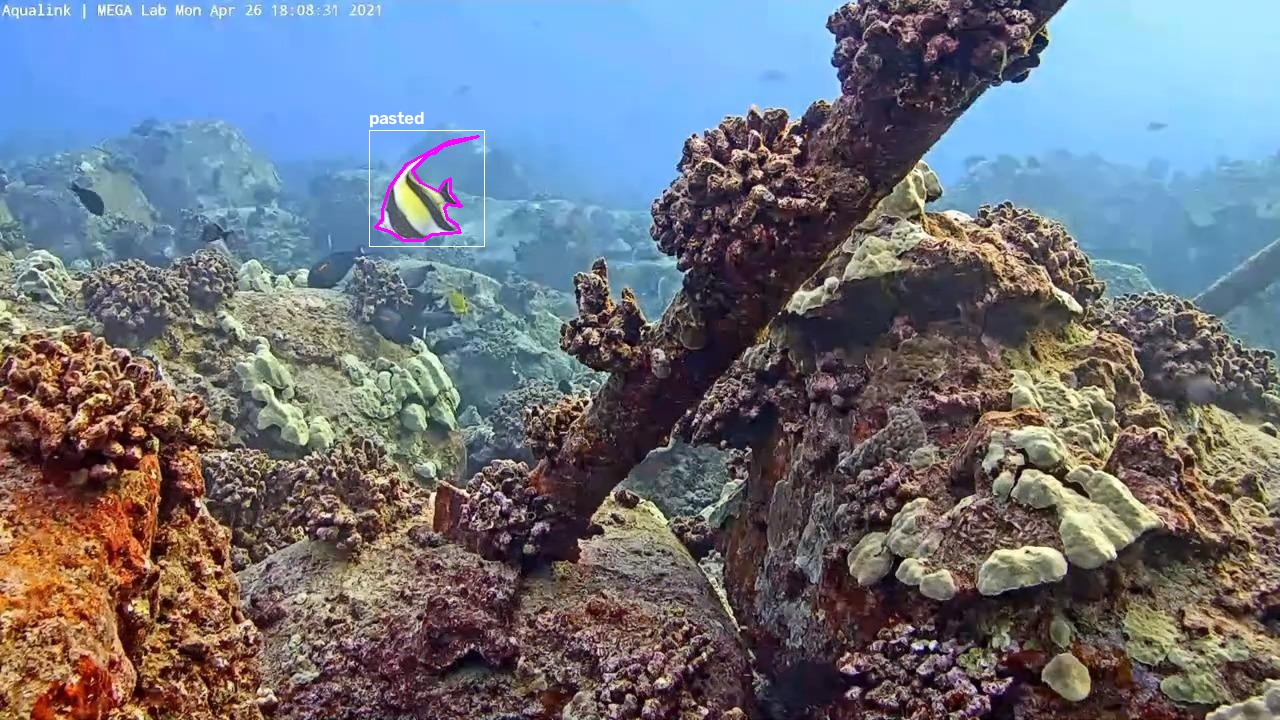

### 7. Forcepsfish: donor frame 164 → target frame 1257
rotated +2°; pasted fish is 35×49 px at x=547, y=148 · file `synth_Forcepsfish_0123_t1257_d164.jpg`

**As the model sees it**

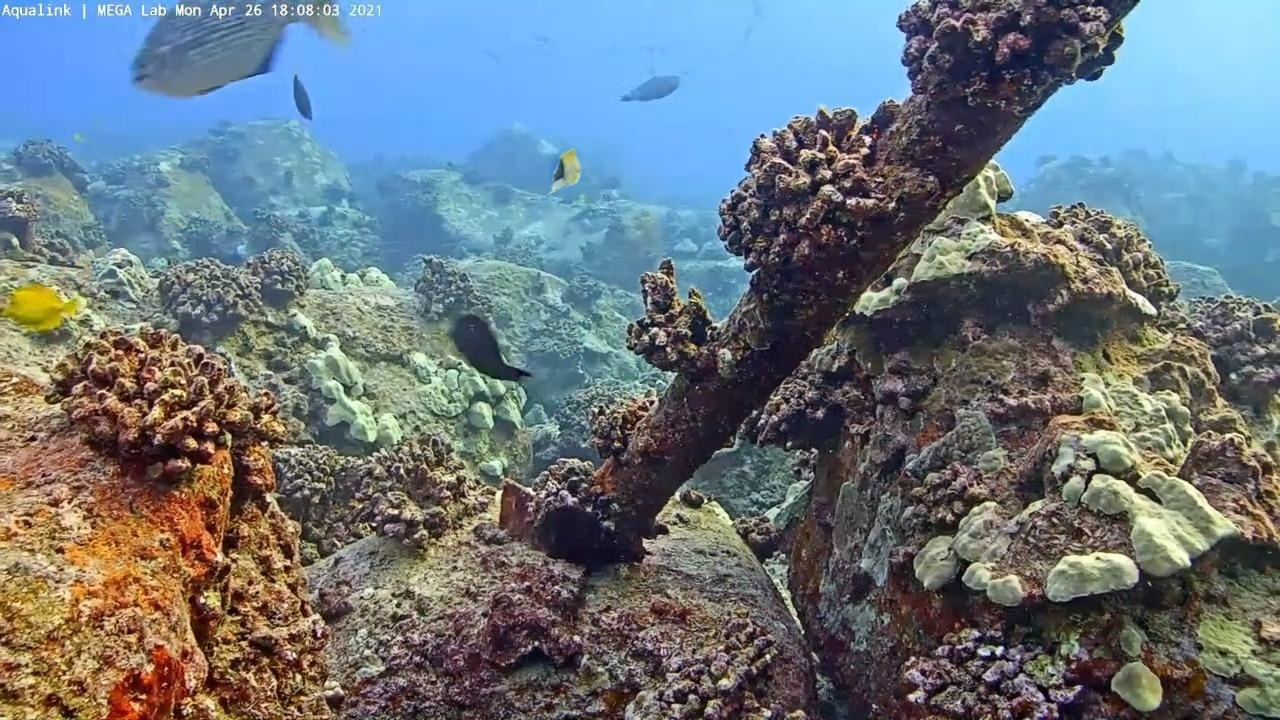

**Pasted fish outlined** (outline drawn from the label file)

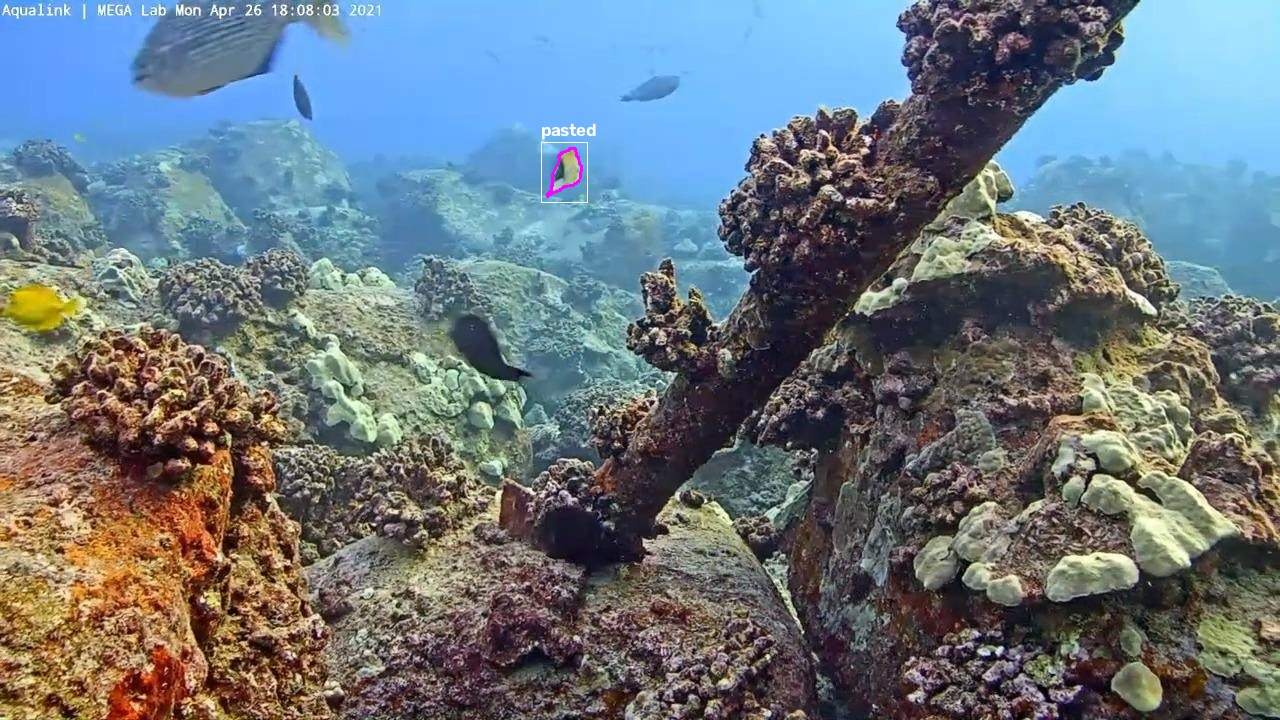

### 8. Moorish Idol: donor frame 1168 → target frame 1666
rotated -16°, flipped horizontally; pasted fish is 69×77 px at x=358, y=619 · file `synth_Moorish_Idol_0059_t1666_d1168.jpg`

**As the model sees it**

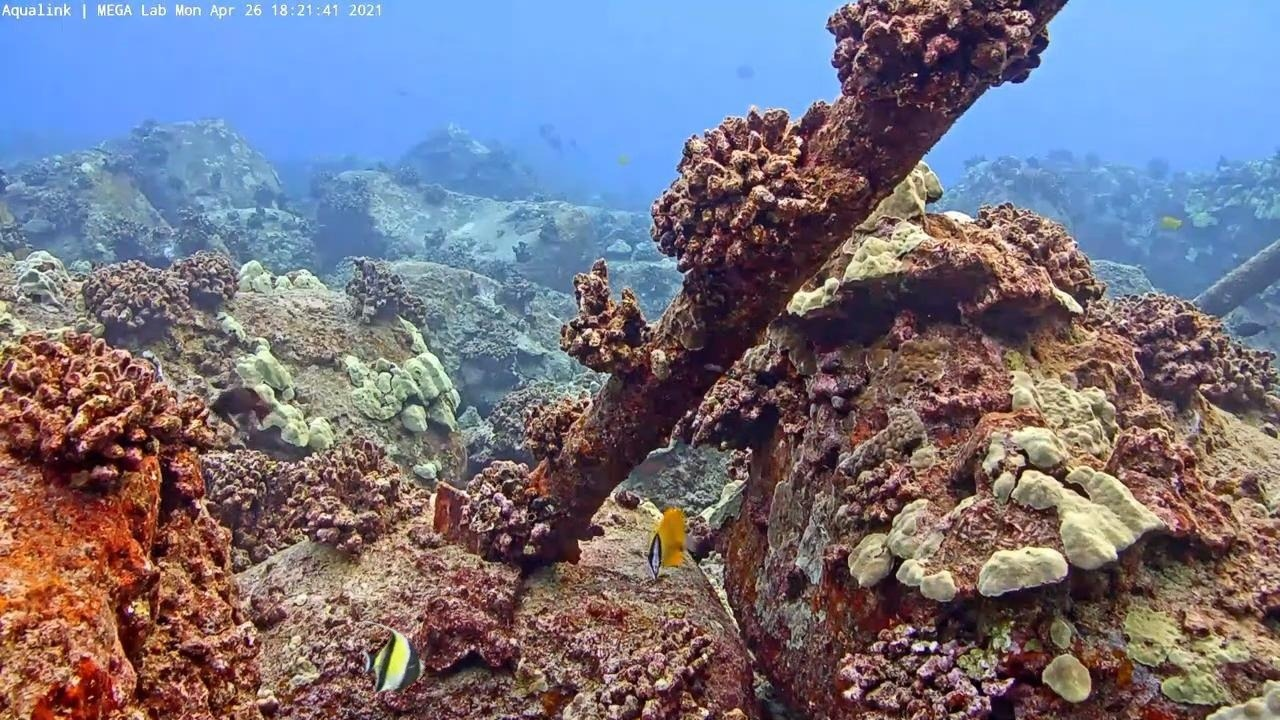

**Pasted fish outlined** (outline drawn from the label file)

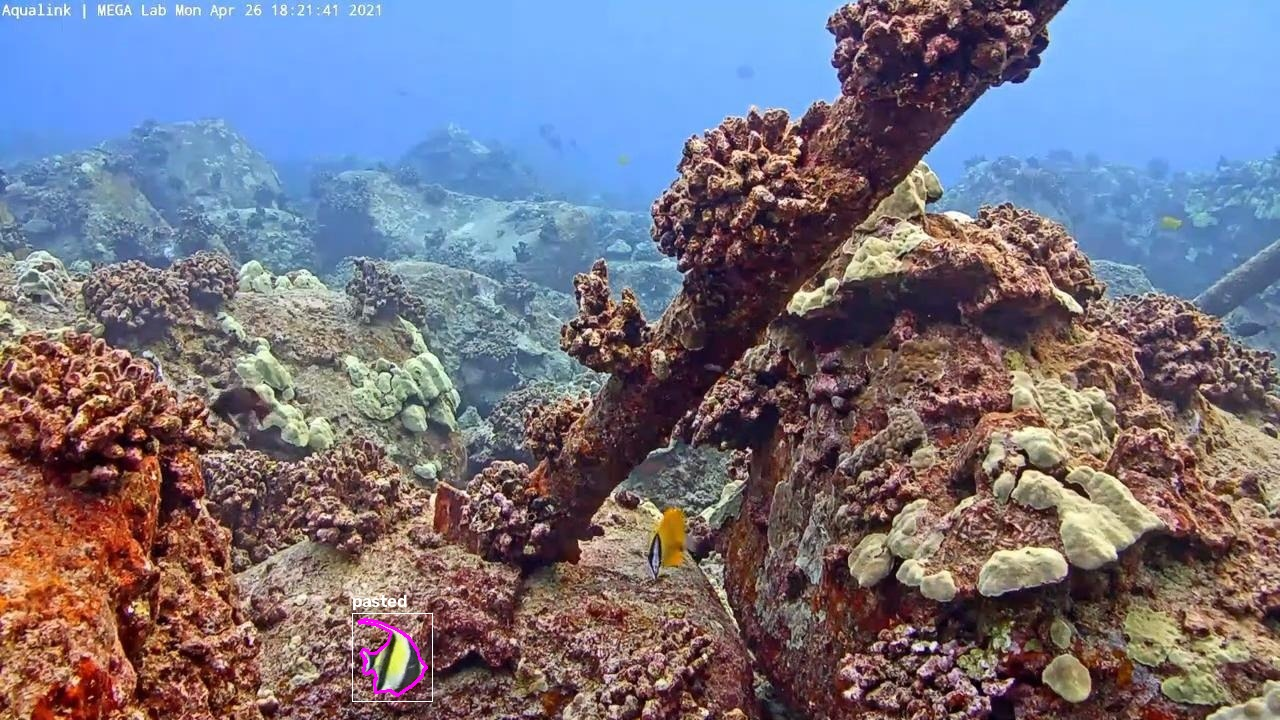

### 9. Forcepsfish: donor frame 1605 → target frame 1296
rotated -3°; pasted fish is 85×84 px at x=556, y=633 · file `synth_Forcepsfish_0095_t1296_d1605.jpg`

**As the model sees it**

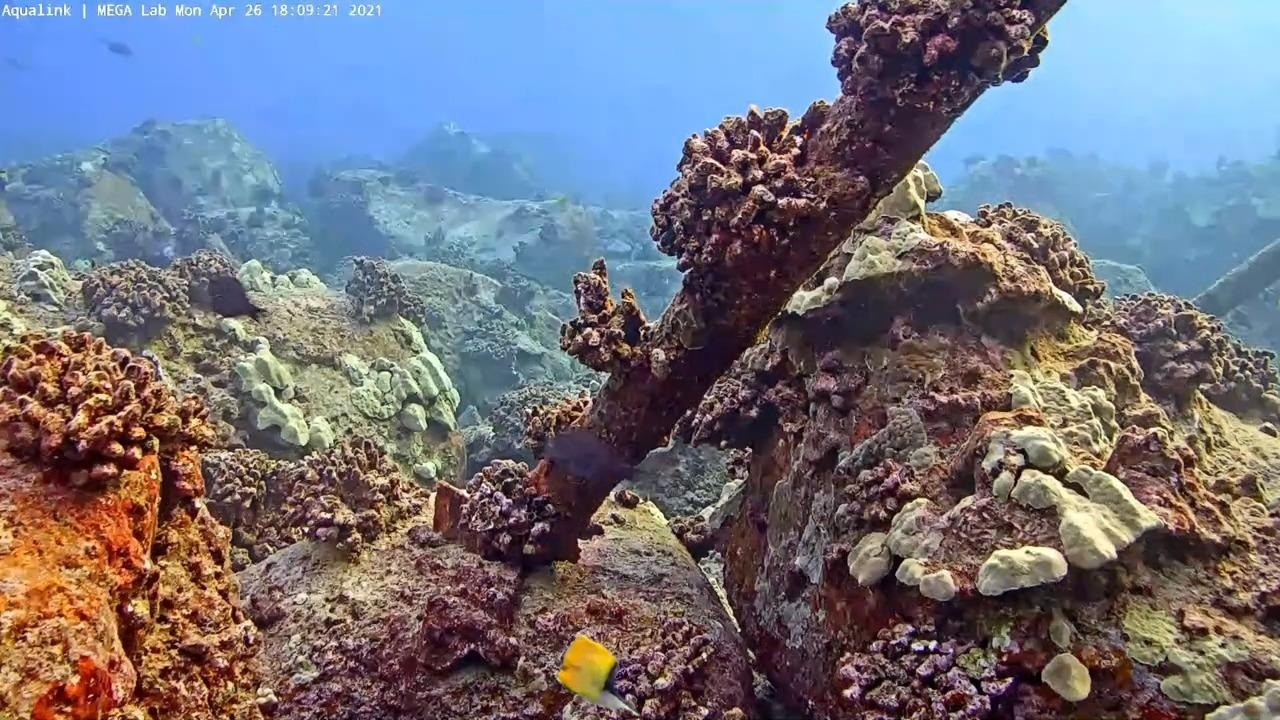

**Pasted fish outlined** (outline drawn from the label file)

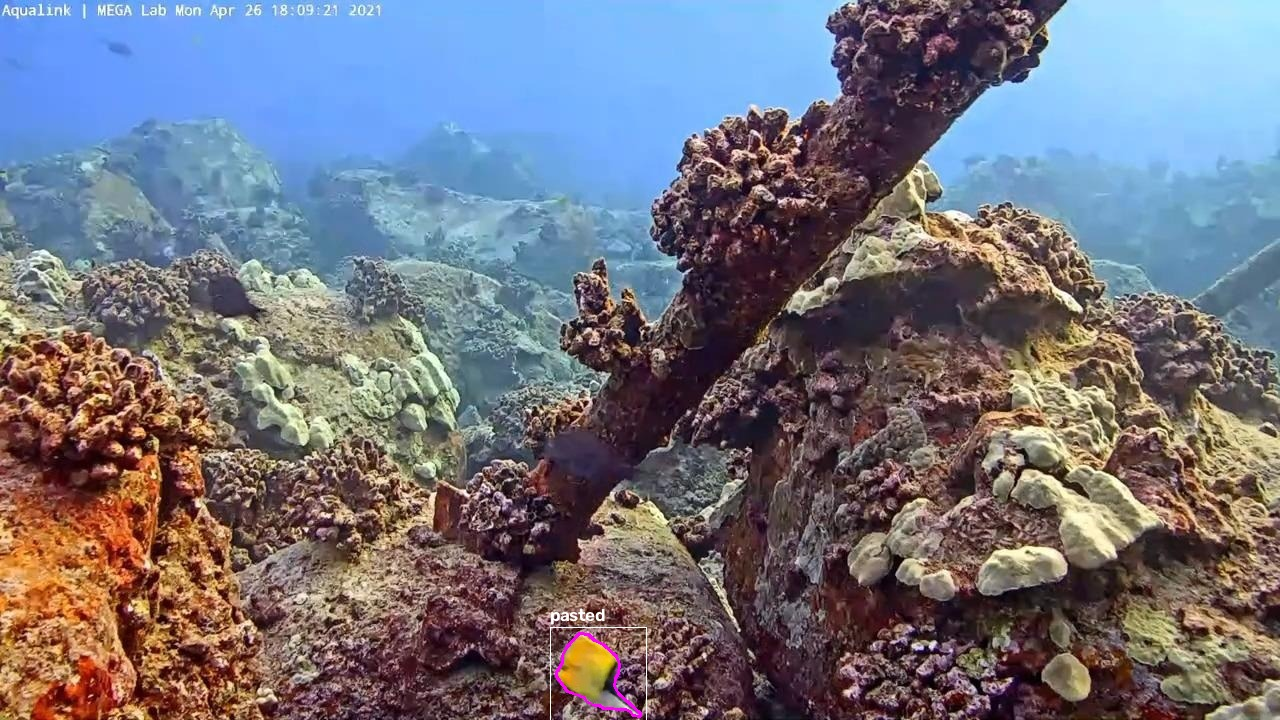

### 10. Moorish Idol: donor frame 1170 → target frame 1303
rotated +12°; pasted fish is 58×64 px at x=643, y=197 · file `synth_Moorish_Idol_0148_t1303_d1170.jpg`

**As the model sees it**

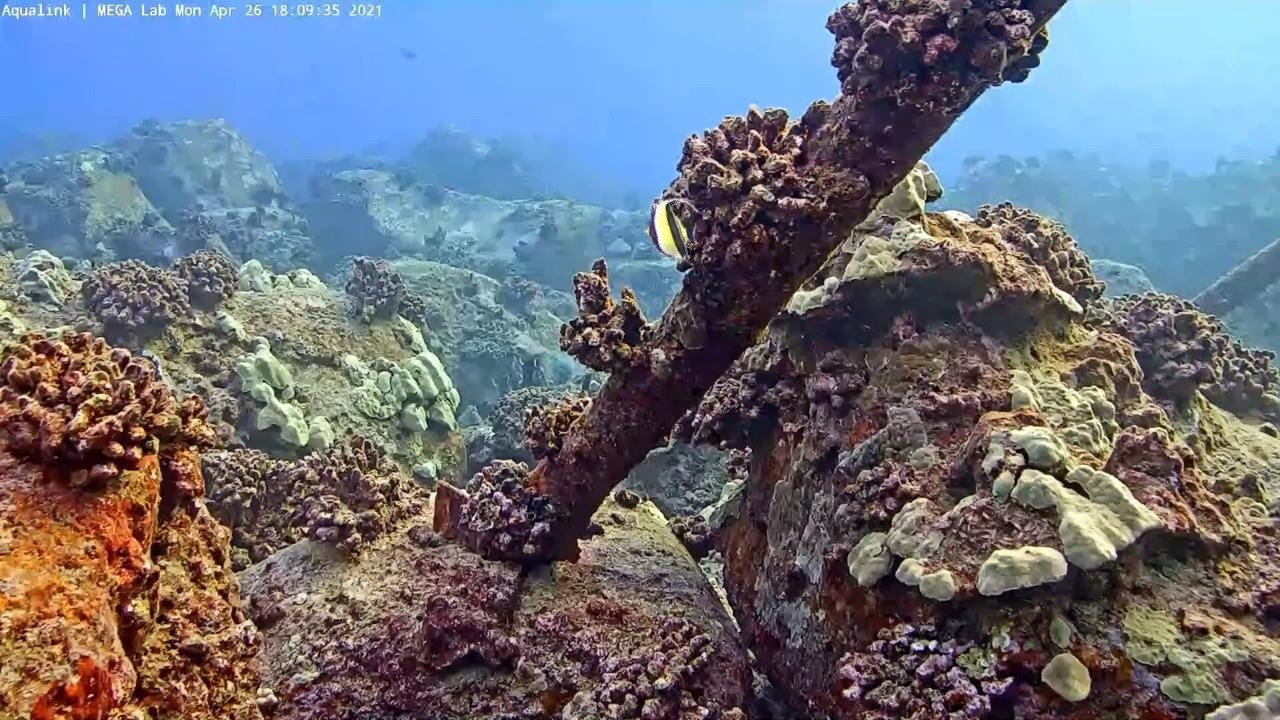

**Pasted fish outlined** (outline drawn from the label file)

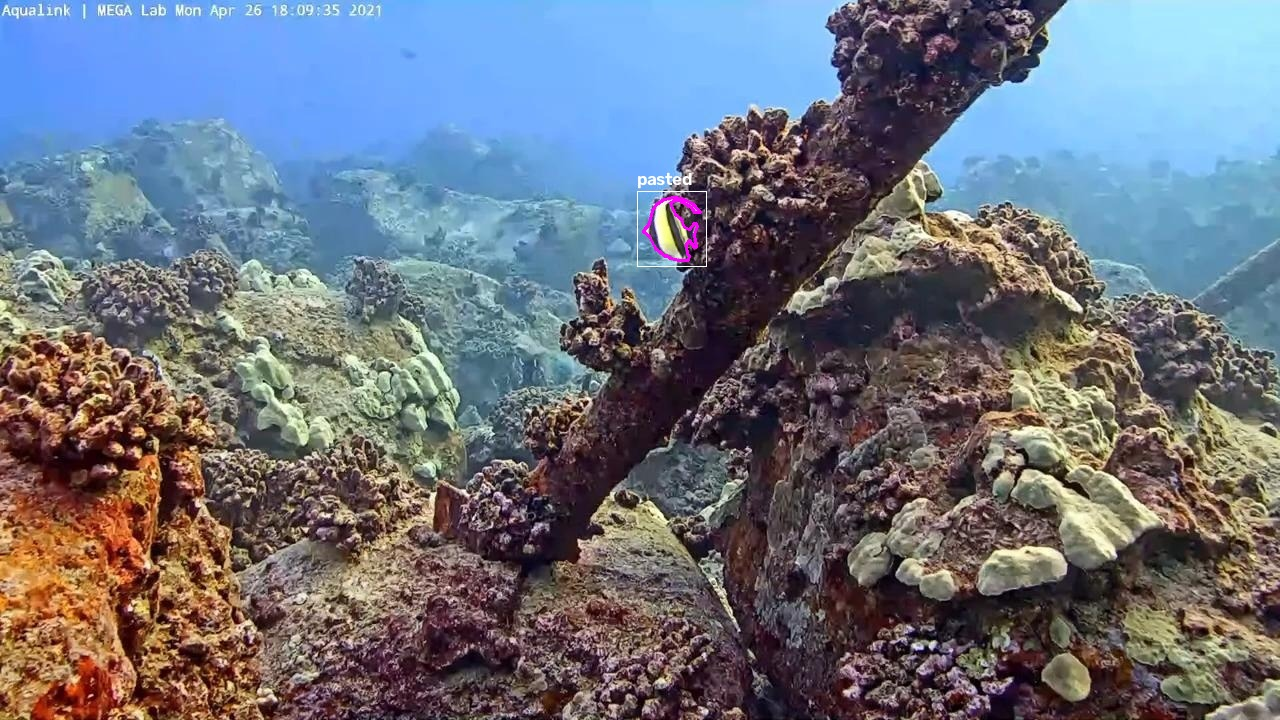

### 11. Forcepsfish: donor frame 2132 → target frame 2159
rotated +15°, flipped horizontally; pasted fish is 36×50 px at x=204, y=65 · file `synth_Forcepsfish_0014_t2159_d2132.jpg`

**As the model sees it**

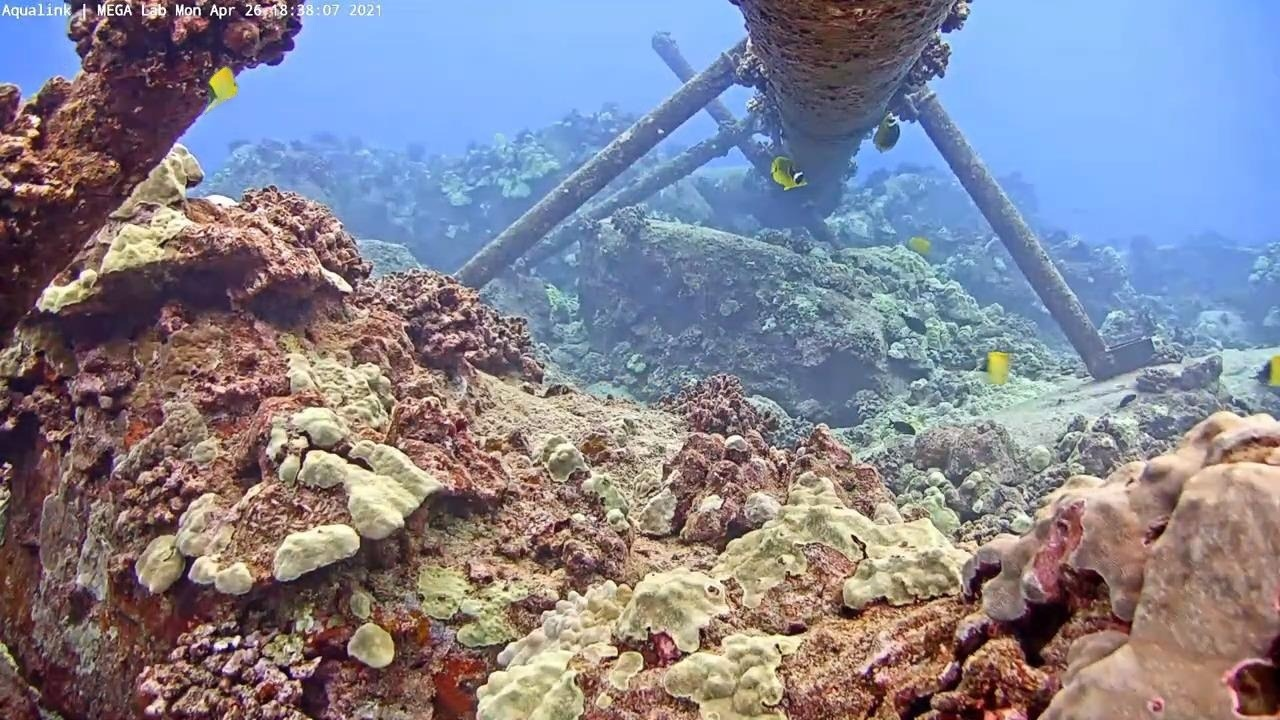

**Pasted fish outlined** (outline drawn from the label file)

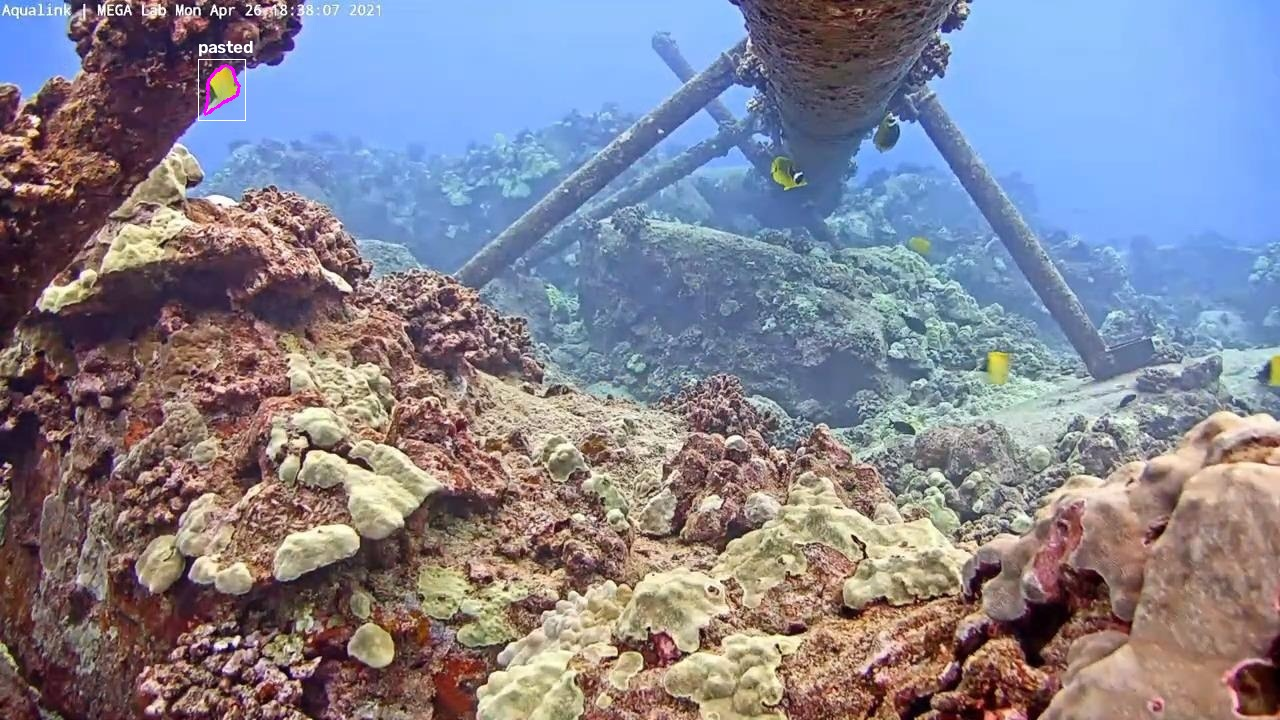

### 12. Moorish Idol: donor frame 1168 → target frame 2448
rotated -14°, flipped horizontally; pasted fish is 66×77 px at x=457, y=464 · file `synth_Moorish_Idol_0088_t2448_d1168.jpg`

**As the model sees it**

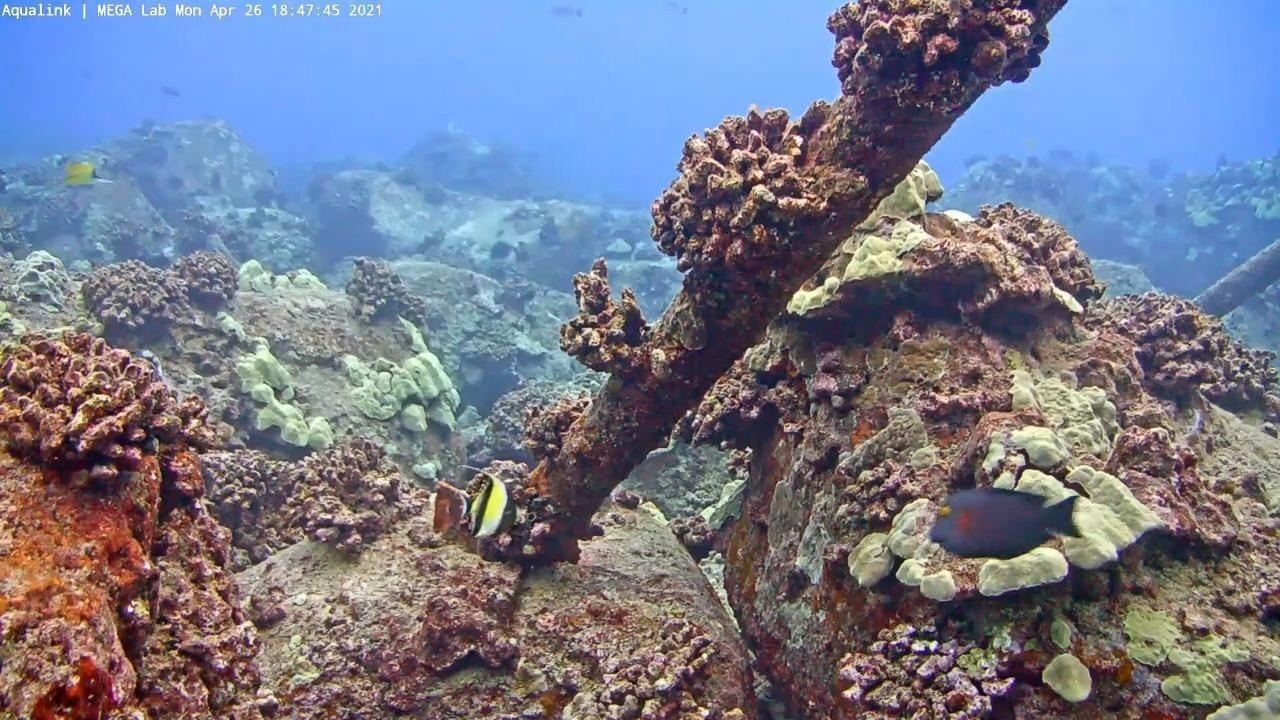

**Pasted fish outlined** (outline drawn from the label file)

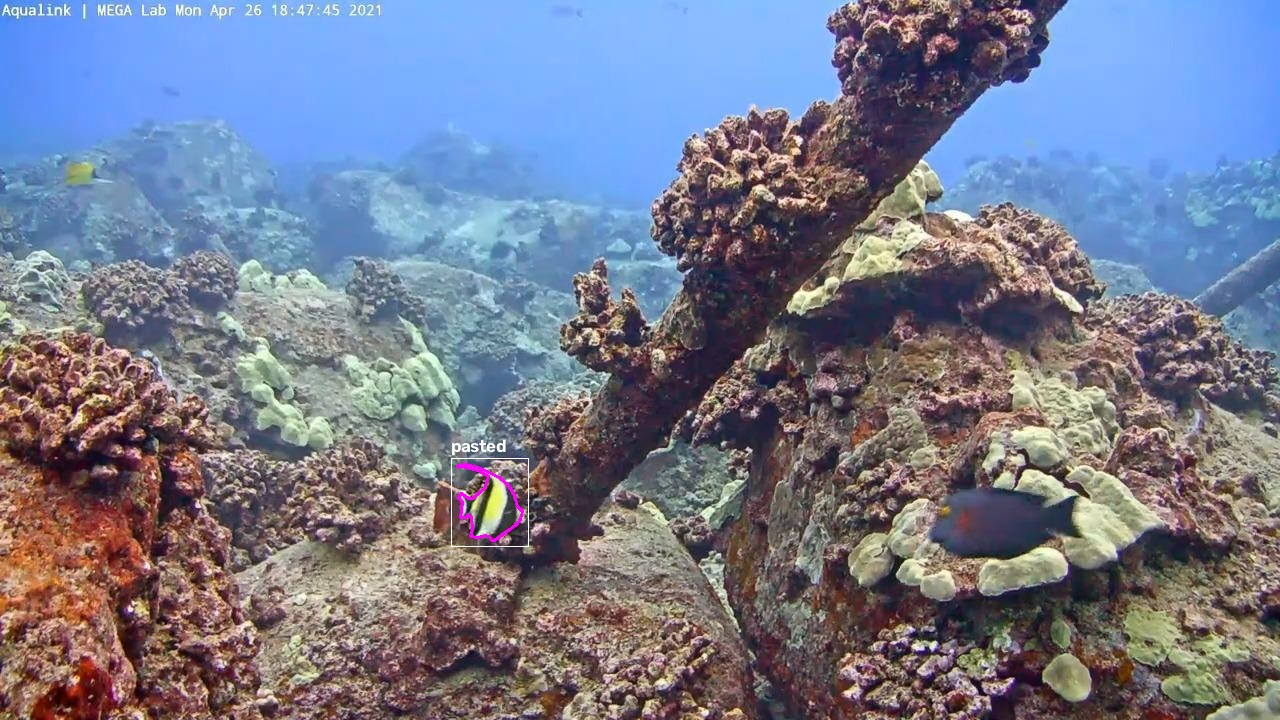

In [4]:
W, H = 1280, 720


def jpeg(img_bgr, quality=92):
    ok, buf = cv2.imencode(".jpg", img_bgr, [cv2.IMWRITE_JPEG_QUALITY, quality])
    return Image(data=buf.tobytes(), format="jpeg", width=img_bgr.shape[1], height=img_bgr.shape[0])


def outlined(img_bgr, label_txt):
    out = img_bgr.copy()
    last = label_txt.strip().splitlines()[-1].split()  # the pasted fish is the last label line
    poly = (np.array(last[1:], float).reshape(-1, 2) * [W, H]).round().astype(np.int32)
    cv2.polylines(out, [poly], True, (255, 0, 255), 2)
    x0, y0 = poly.min(0)
    x1, y1 = poly.max(0)
    cv2.rectangle(out, (x0 - 6, y0 - 6), (x1 + 6, y1 + 6), (255, 255, 255), 1)
    cv2.putText(out, "pasted", (x0 - 6, max(14, y0 - 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
    return out


pool = [r for r in report if SPECIES == "both" or r["species"] == SPECIES]
rng = random.Random(SEED)
if SPECIES == "both":  # alternate species so both show up
    by_sp = {sp: [r for r in pool if r["species"] == sp] for sp in sorted({r["species"] for r in pool})}
    for v in by_sp.values():
        rng.shuffle(v)
    picks = [r for group in zip(*by_sp.values()) for r in group][:N_SAMPLES]
else:
    picks = rng.sample(pool, min(N_SAMPLES, len(pool)))

for i, r in enumerate(picks, 1):
    img = cv2.imread(str(PREVIEW / "synth_images" / f"{r['synth']}.jpg"))
    lbl = (PREVIEW / "labels" / f"{r['synth']}.txt").read_text()
    flip = ", flipped horizontally" if r["hflip"] == "1" else ""
    display(Markdown(f"### {i}. {r['species']}: donor frame {r['donor_frame']} → target frame {r['target_frame']}\n"
                     f"rotated {float(r['angle']):+.0f}°{flip}; pasted fish is {r['w']}×{r['h']} px at "
                     f"x={r['x']}, y={r['y']} · file `{r['synth']}.jpg`"))
    if SHOW_ORIGINAL:
        display(Markdown("**Before** (original target frame)"))
        display(jpeg(cv2.imread(str(IMAGES_DIR / f"frame_{r['target_frame']}.jpg"))))
    display(Markdown("**As the model sees it**"))
    display(jpeg(img))
    display(Markdown("**Pasted fish outlined** (outline drawn from the label file)"))
    display(jpeg(outlined(img, lbl)))